# 02d - NEWAVE: decks de jan, fev e mar/2026 — cor pela média × cor pela mediana

Método do **cenário mesma série** (GSF e preço das mesmas 25 séries escolhidas pela trajetória de ENA), agora com o deck
de **março/2026**. A cor exibida é calculada de duas formas, em figuras separadas:

- **Média:** ábaco com o GSF médio e o PLD médio das 25 séries.
- **Mediana:** primeira cor (verde → vermelha 2) com probabilidade acumulada ≥ 50%.

O texto de cada célula traz a distribuição das 25 séries. Não há curva Dcide para o deck de março (linha em cinza).
A ENA de referência é a real (oráculo). Figuras em `reports/figures/cenario_3decks/`.

In [1]:
import pandas as pd
from IPython.display import Image, display

from forecast_bandeiras import graficos, load, newave, regra

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
base = pd.read_parquet(load.DATA_PROCESSED / "base_mensal.parquet").loc["2026"]
base.index = base.index.month
base["cor_oficial"] = [c if isinstance(c, str) else r for c, r in zip(base.cor_boletim, base.cor_regra)]
ALVOS = [5, 6, 8, 10]
ABREV = {"Verde": "Vd", "Amarela": "Am", "Vermelha 1": "V1", "Vermelha 2": "V2"}
PASTA = "cenario_3decks"


def texto_prob(prob):
    itens = [f"{ABREV[c]} {v:.0%}" for c, v in prob.items() if v >= 0.05]
    return " ".join(itens[:2]) + ("\n" + " ".join(itens[2:]) if len(itens) > 2 else "")


def ler_dcide_ou_vazio(mes_deck):
    try:
        dc = load.ler_dcide(2026, mes_deck)
    except StopIteration:
        return pd.Series(dtype=float)
    dc = dc[dc.index.year == 2026]
    dc.index = dc.index.month
    return dc

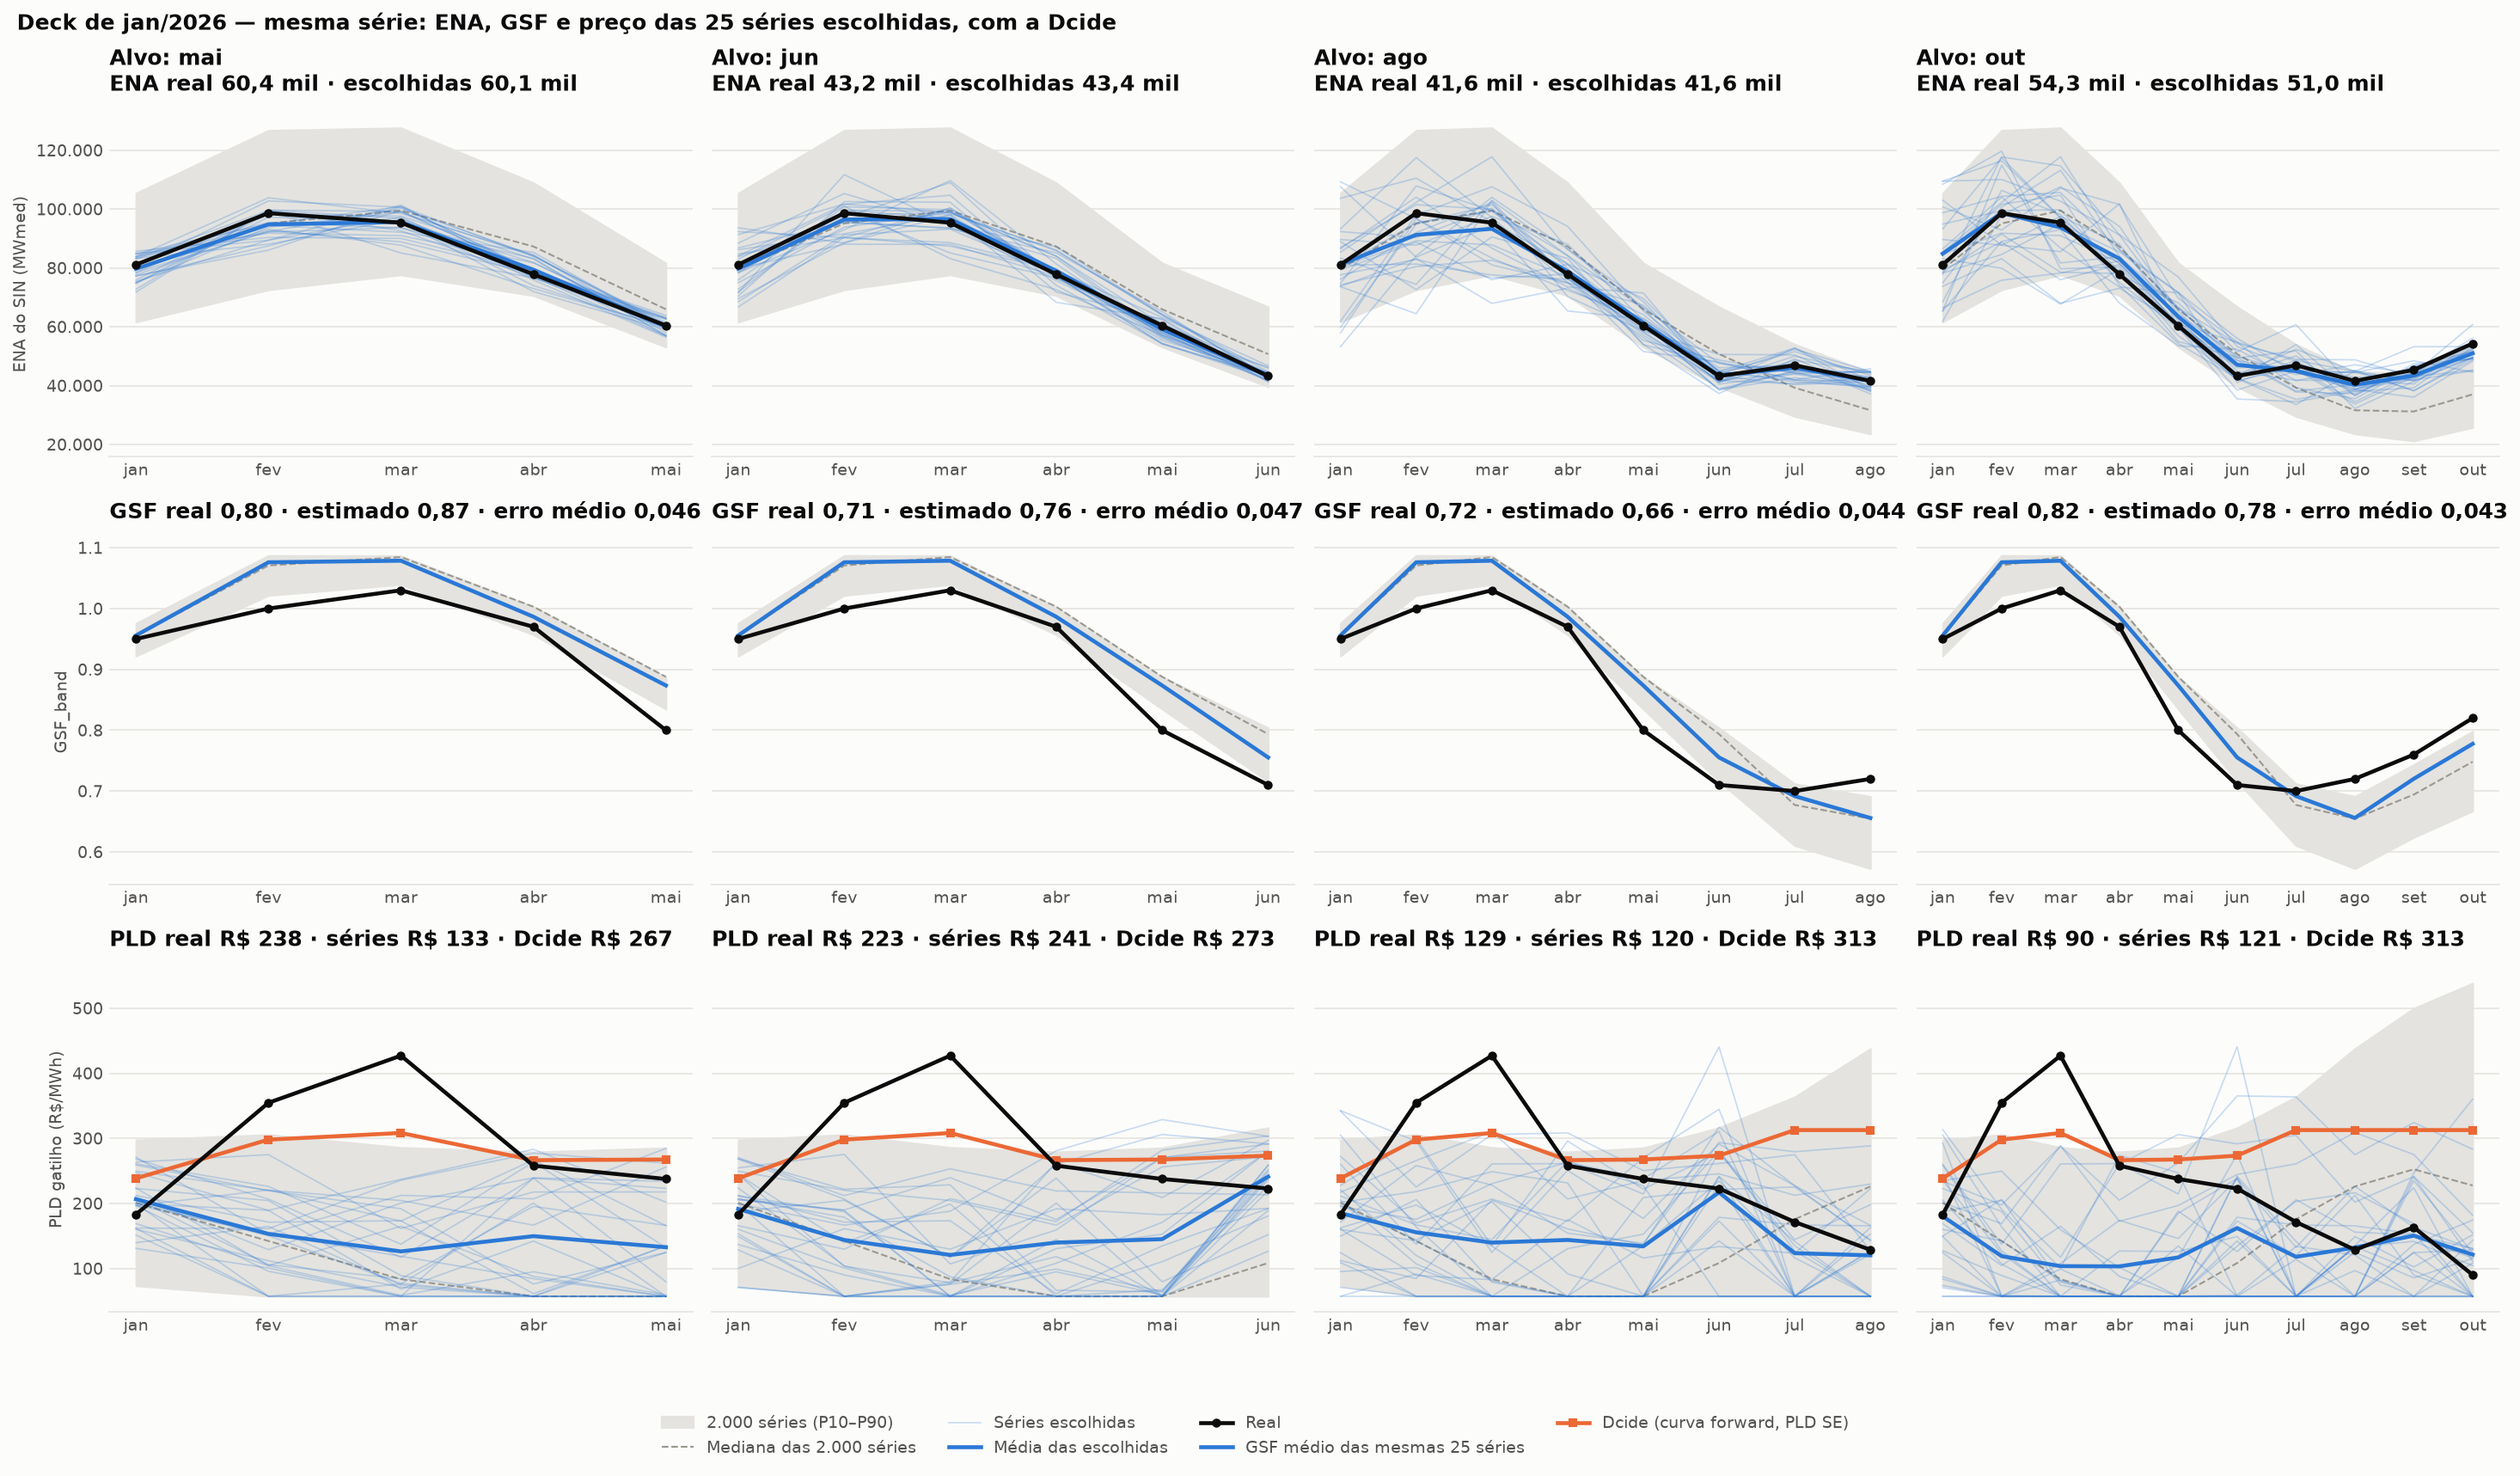

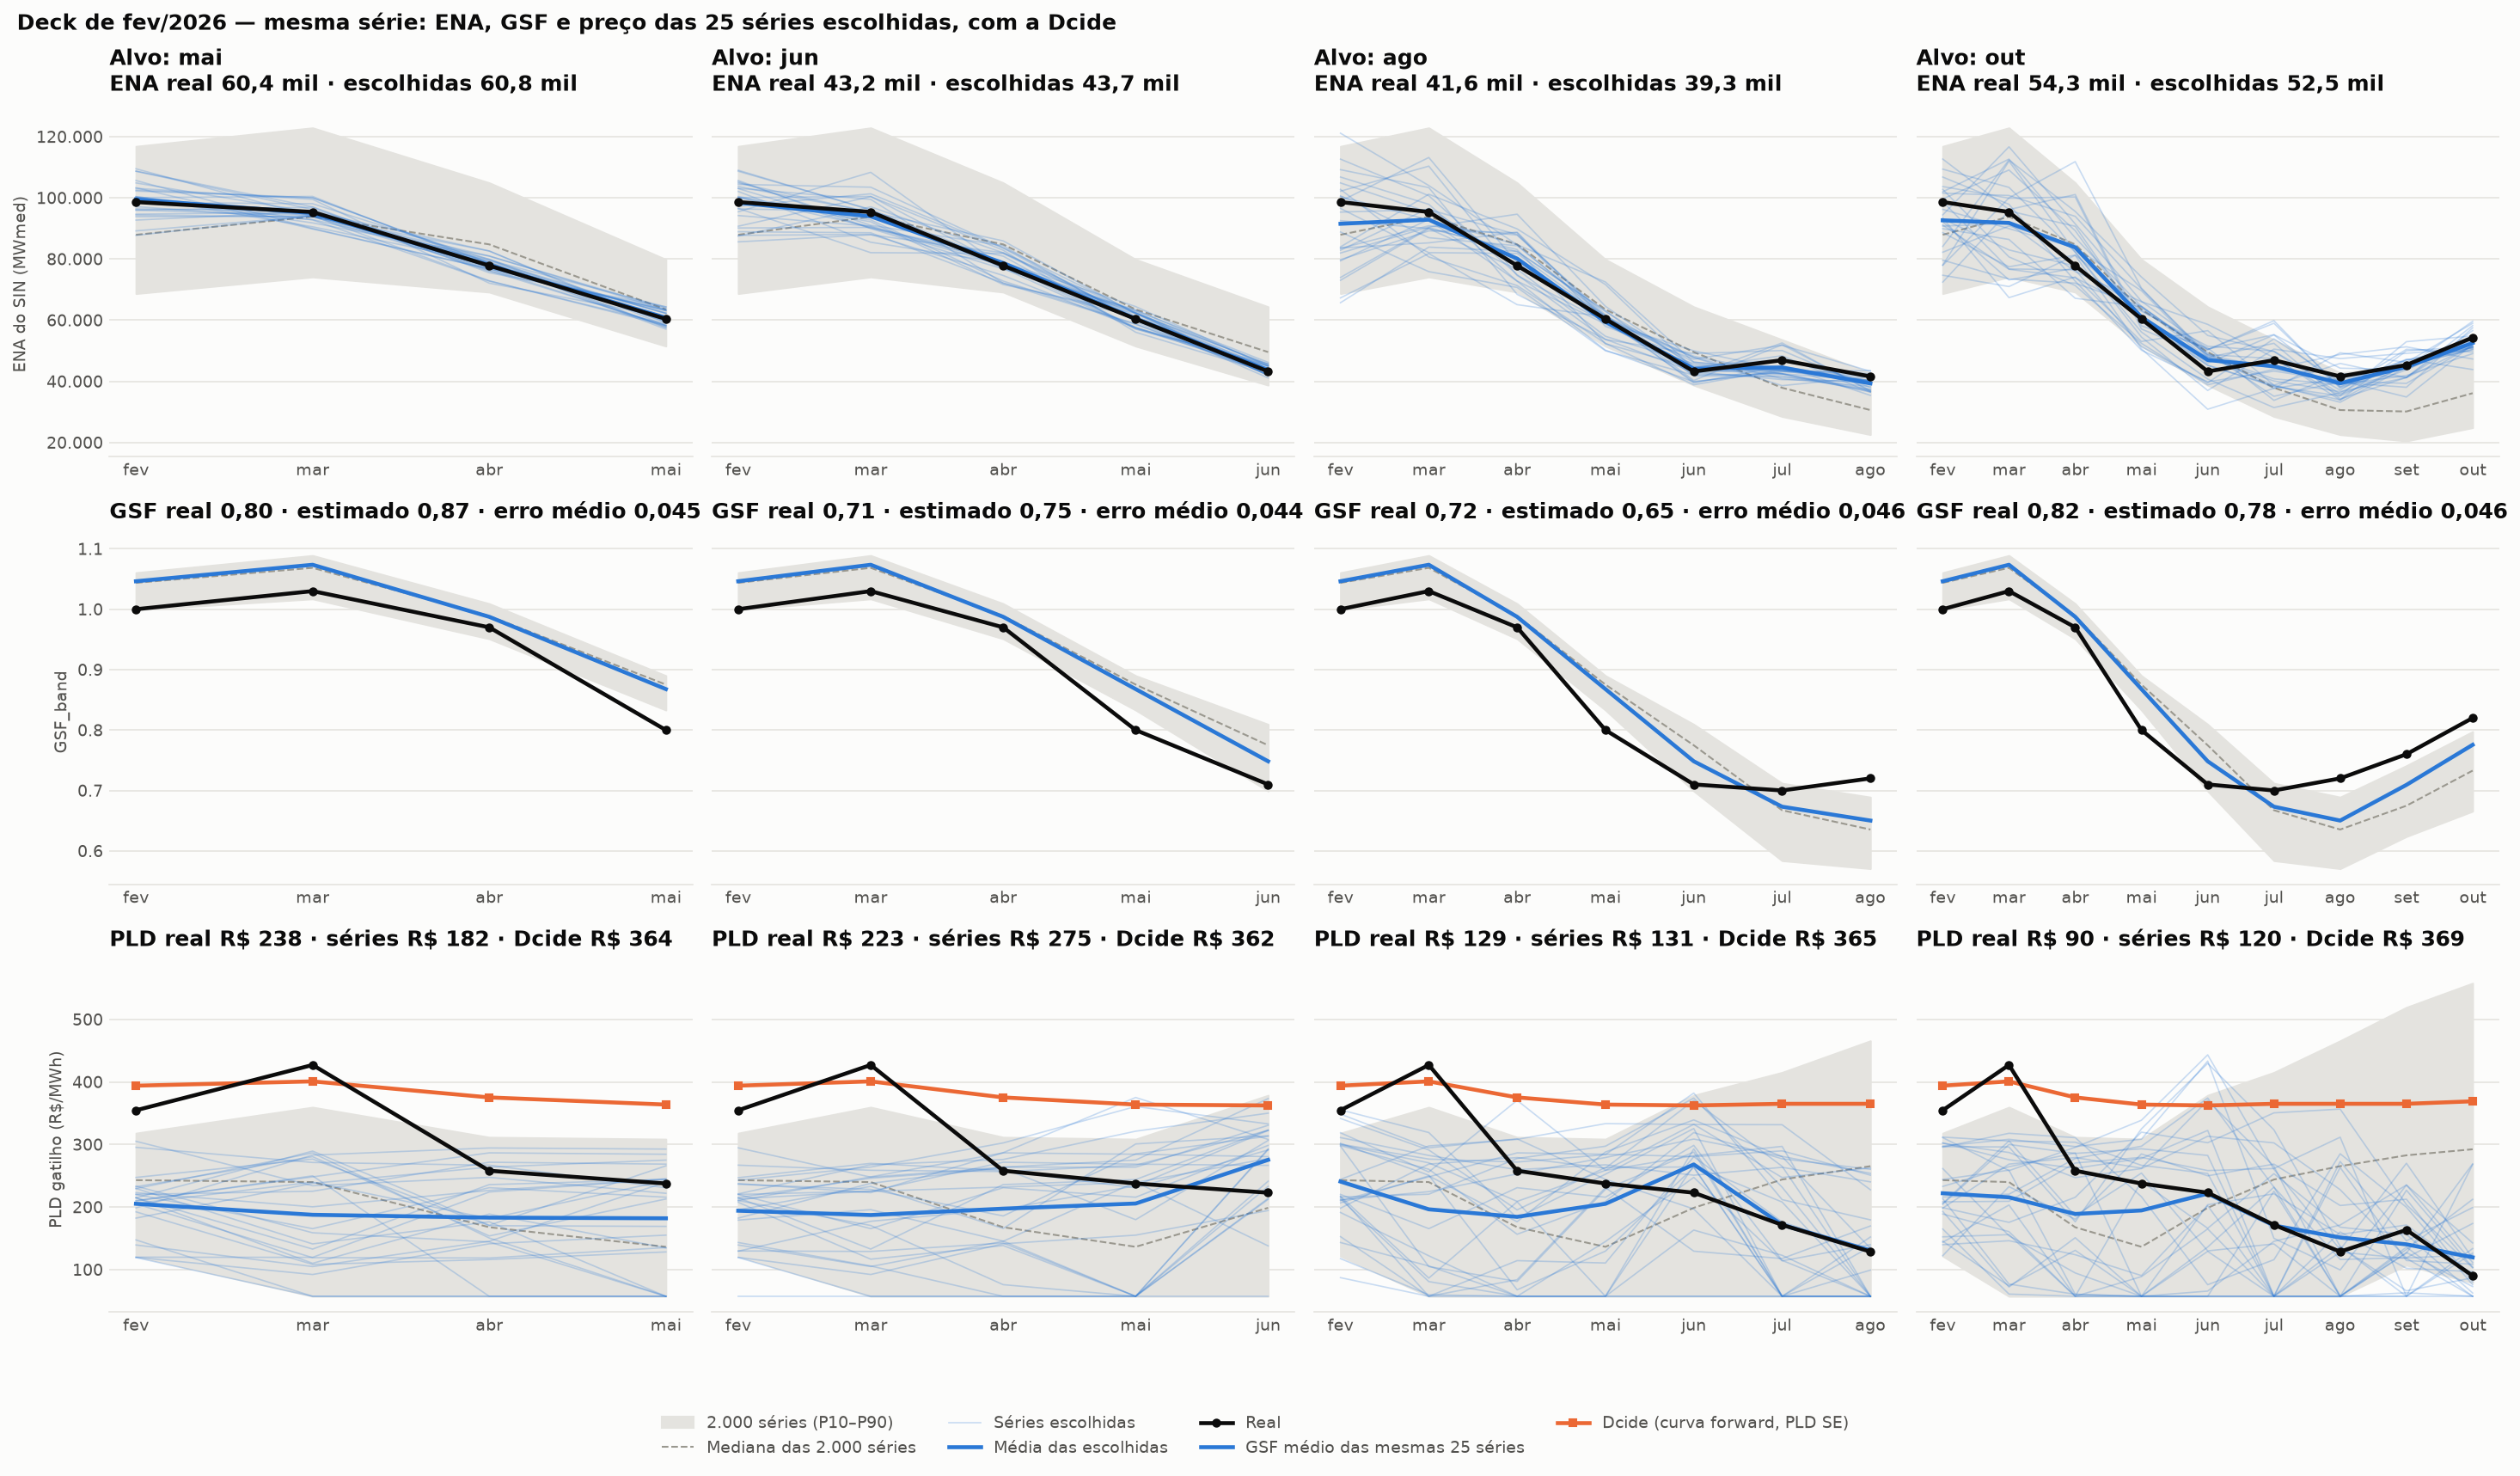

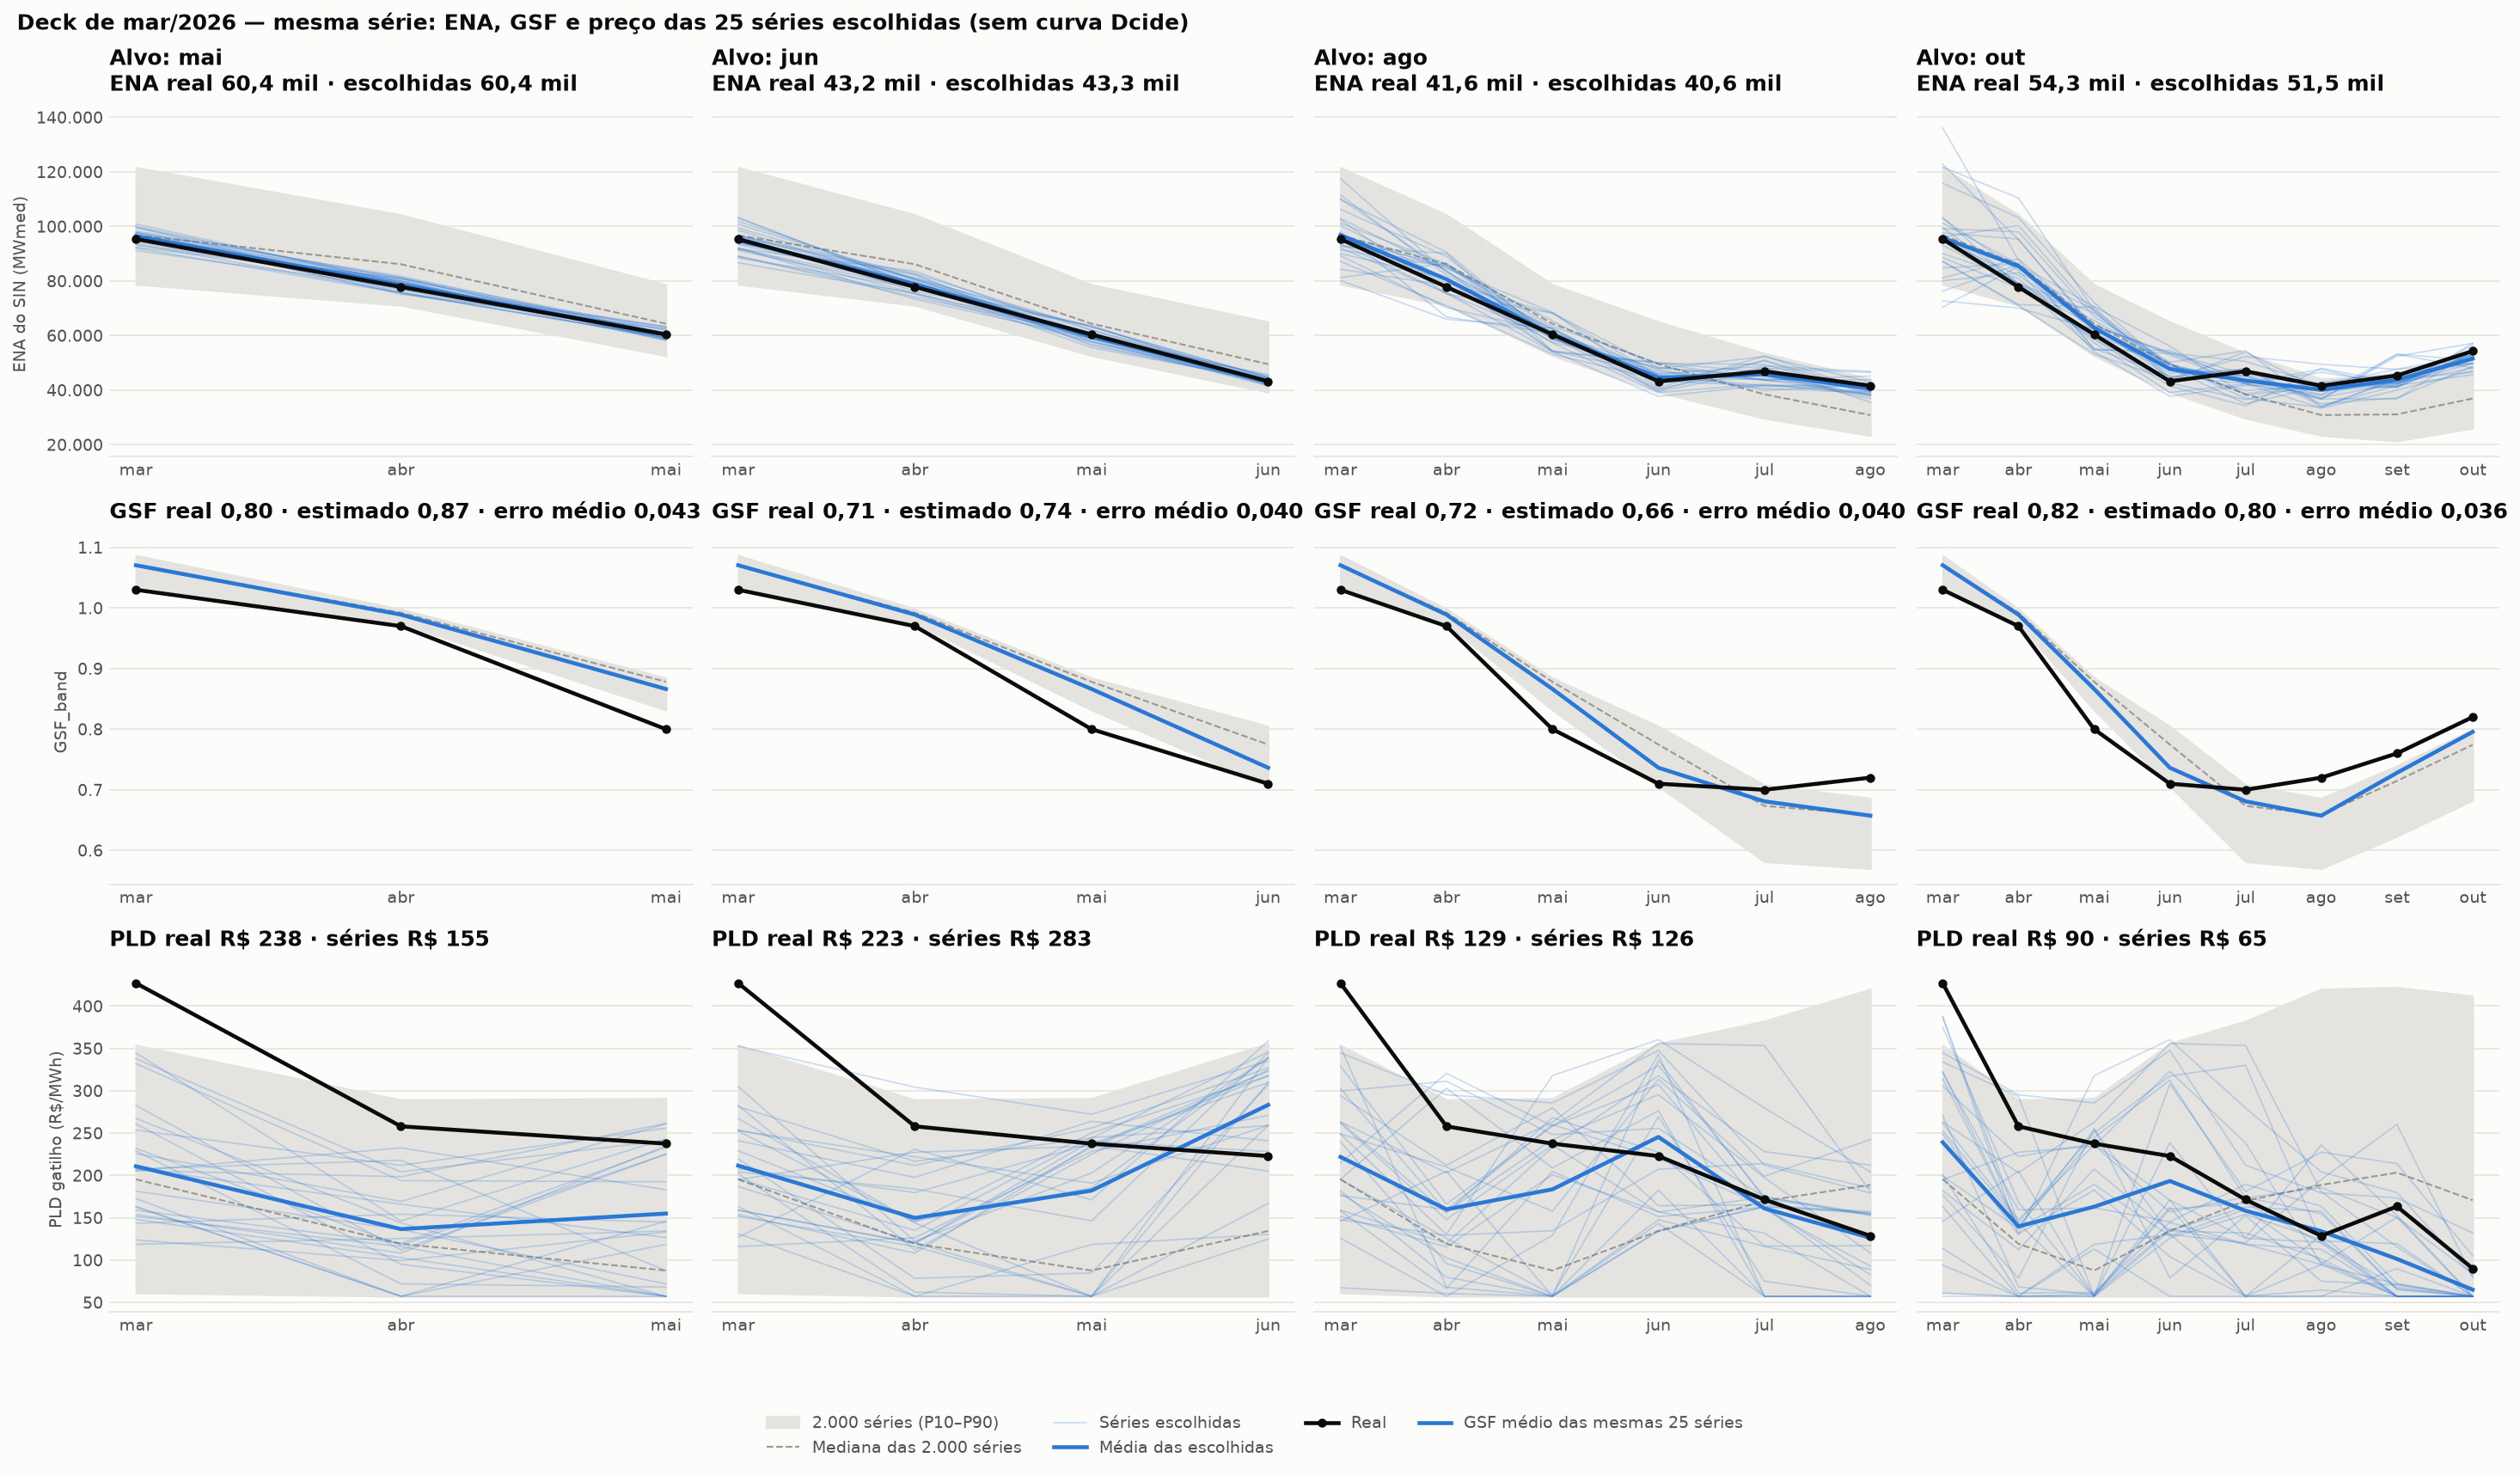

In [2]:
tab_media, tab_mediana, comparacao = {}, {}, []
for mes_deck in (1, 2, 3):
    deck = newave.carregar_deck(2026, mes_deck)
    meses = list(range(mes_deck, 11))
    ena = deck["ena_sin"][meses]
    gsf = newave.gsf_series(deck, base.loc[meses])
    pld = newave.pld_gatilho_series(deck, meses, base.pld_min_boletim.iloc[0], base.pld_max_boletim.max())
    dcide = ler_dcide_ou_vazio(mes_deck)
    esc = {m: newave.escolher_series(ena, base.loc[mes_deck:m, "ena_sin"], k=25) for m in meses}
    nome = f"{graficos.MESES[mes_deck - 1]}/2026"
    display(Image(graficos.trajetorias_deck(
        ena, gsf, pld, base, {a: esc[a] for a in ALVOS}, esc, dcide,
        f"Deck de {nome} — mesma série: ENA, GSF e preço das 25 séries escolhidas"
        + (", com a Dcide" if not dcide.empty else " (sem curva Dcide)"),
        f"{PASTA}/08_trajetorias_deck_{mes_deck:02d}.png", rotulo_gsf="GSF médio das mesmas 25 séries")))
    lin_media, lin_mediana = {}, {}
    for m in meses:
        real = base.loc[m, "cor_oficial"]
        g, p = gsf.loc[esc[m], m], pld.loc[esc[m], m]
        gsf_med = round(g.mean(), 2)
        prob = newave.probabilidade_cores_pareada(g, p)
        tem_dc = m in dcide.index
        prob_dc = newave.probabilidade_cores_pareada(g, pd.Series(dcide.loc[m], index=g.index)) if tem_dc else None
        cores = {
            "séries — média": regra.cor_bandeira(gsf_med, p.mean()),
            "séries — mediana": newave.cor_mediana(prob),
            "Dcide — média": regra.cor_bandeira(gsf_med, dcide.loc[m]) if tem_dc else None,
            "Dcide — mediana": newave.cor_mediana(prob_dc) if tem_dc else None,
        }
        comum = {"cor_real": real, "prob_series": texto_prob(prob)}
        lin_media[m] = {**comum, "cor_series": cores["séries — média"], "cor_dcide": cores["Dcide — média"],
                        "prob_dcide": texto_prob(prob_dc) if tem_dc else ""}
        lin_mediana[m] = {**comum, "cor_series": cores["séries — mediana"], "cor_dcide": cores["Dcide — mediana"],
                          "prob_dcide": texto_prob(prob_dc) if tem_dc else ""}
        comparacao.append({"deck": nome, "mes": m, "real": real, **cores,
                           "erro GSF": abs(gsf_med - base.loc[m, "gsf_band_boletim"]),
                           "erro PLD": p.mean() - base.loc[m, "pld_gatilho_boletim"],
                           "prob. da cor real": prob[real]})
    tab_media[f"Deck de {nome}"] = pd.DataFrame(lin_media).T
    tab_mediana[f"Deck de {nome}"] = pd.DataFrame(lin_mediana).T

## Bandeira com a cor pela **média**

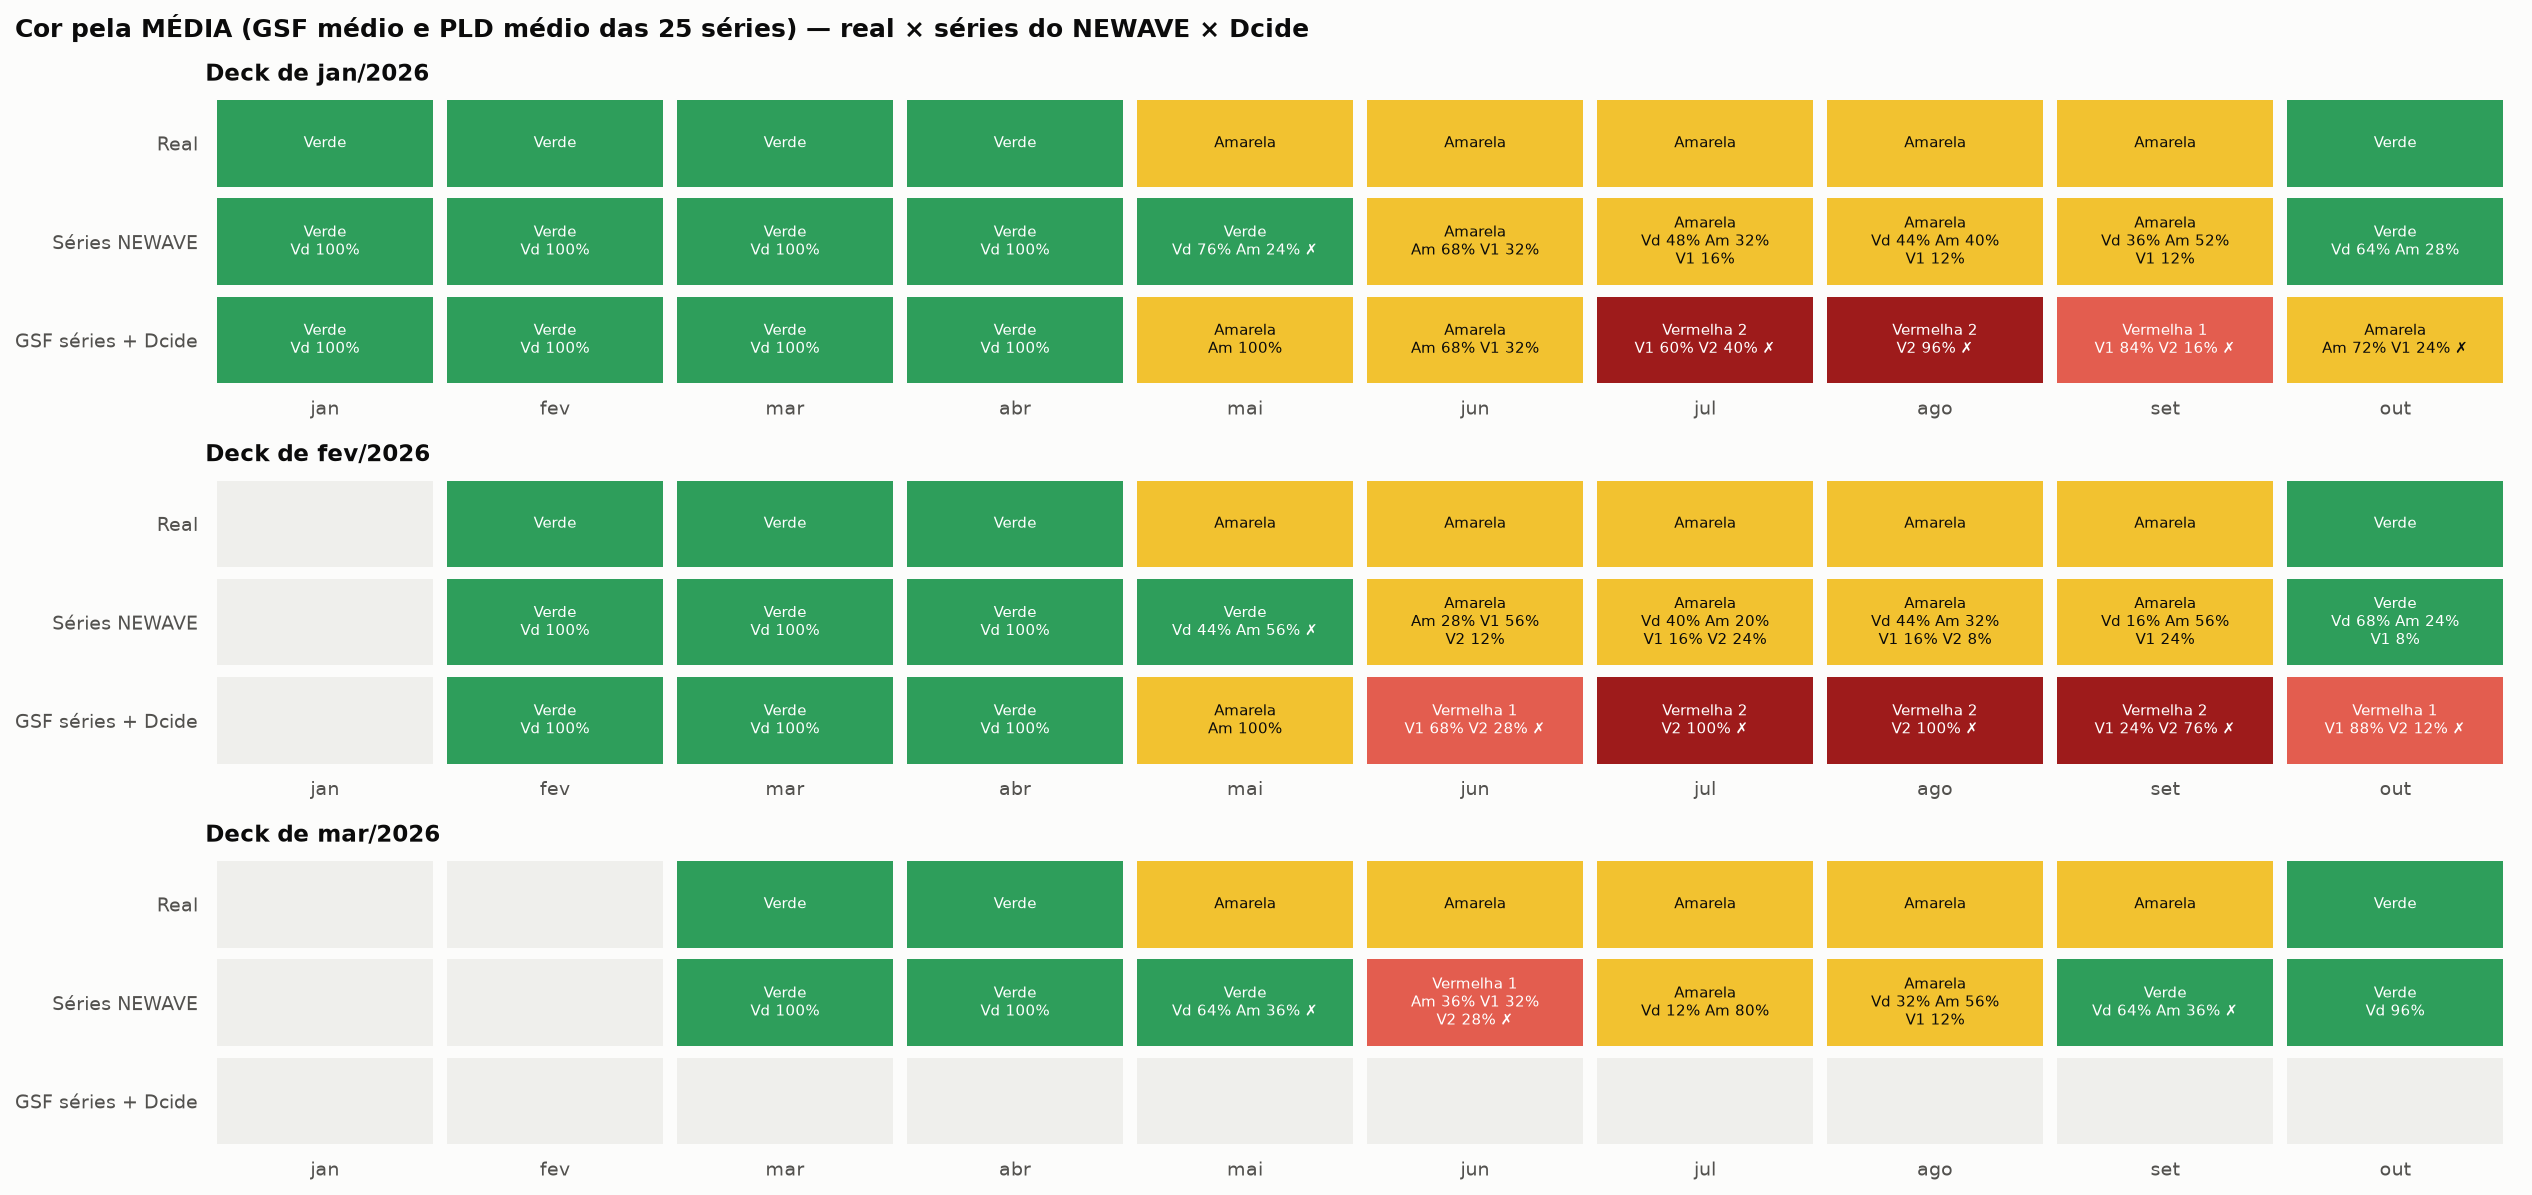

In [3]:
display(Image(graficos.faixa_bandeiras(
    tab_media, "Cor pela MÉDIA (GSF médio e PLD médio das 25 séries) — real × séries do NEWAVE × Dcide",
    f"{PASTA}/09_bandeiras_media.png")))

## Bandeira com a cor pela **mediana**

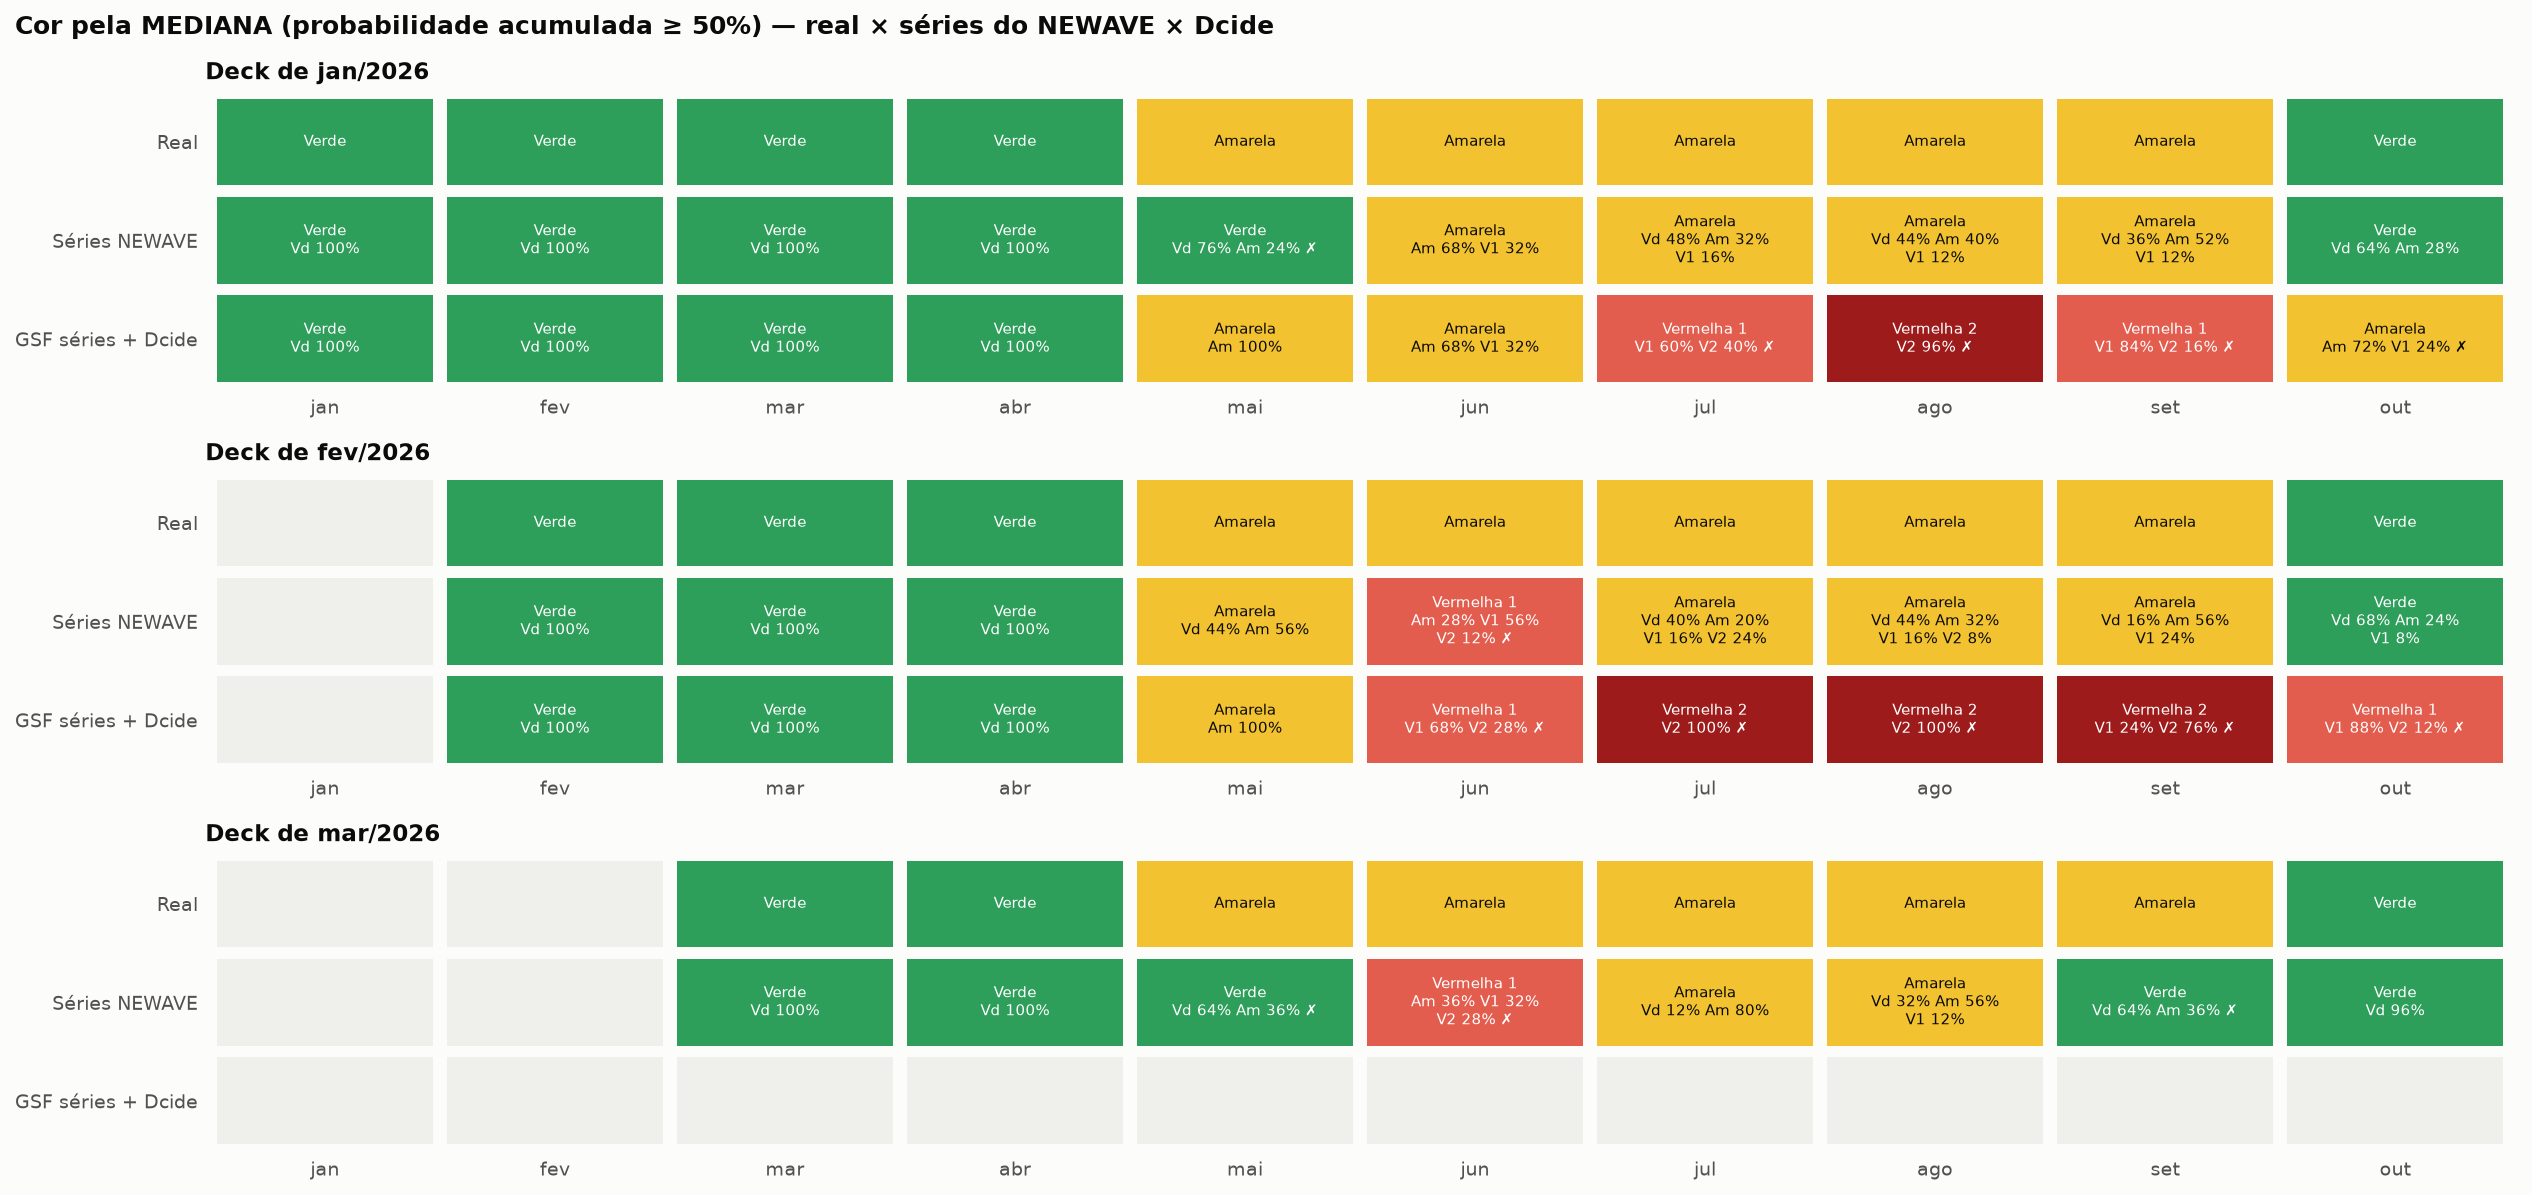

In [4]:
display(Image(graficos.faixa_bandeiras(
    tab_mediana, "Cor pela MEDIANA (probabilidade acumulada ≥ 50%) — real × séries do NEWAVE × Dcide",
    f"{PASTA}/09_bandeiras_mediana.png")))

## Comparação

In [5]:
comp = pd.DataFrame(comparacao)
regras = ["séries — média", "séries — mediana", "Dcide — média", "Dcide — mediana"]
acertos = pd.DataFrame({r: comp.groupby("deck", sort=False).apply(
    lambda d, r=r: f"{(d[r] == d.real).sum()}/{d[r].notna().sum()}") for r in regras})
acertos["erro médio GSF"] = comp.groupby("deck", sort=False)["erro GSF"].mean()
acertos["erro médio |PLD|"] = comp.groupby("deck", sort=False)["erro PLD"].apply(lambda x: x.abs().mean())
acertos["prob. média da cor real"] = comp.groupby("deck", sort=False)["prob. da cor real"].mean()
acertos

,séries — média,séries — mediana,Dcide — média,Dcide — mediana,erro médio GSF,erro médio |PLD|,prob. média da cor real
deck,,,,,,,
jan/2026,9/10,9/10,6/10,6/10,0.043,90.045,0.680
fev/2026,8/9,8/9,4/9,4/9,0.046,68.958,0.622
mar/2026,5/8,5/8,0/0,0/0,0.036,75.237,0.675


In [6]:
comp[comp["séries — média"] != comp["séries — mediana"]][["deck", "mes", "real", "séries — média", "séries — mediana", "prob. da cor real"]]

,deck,mes,real,séries — média,séries — mediana,prob. da cor real
13,fev/2026,5,Amarela,Verde,Amarela,0.560
14,fev/2026,6,Amarela,Amarela,Vermelha 1,0.280
